# 高斯贝叶斯模型

## 符合正态分布

In [1]:
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB

X, y = make_blobs(n_samples=400, centers=4, random_state=0)


X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=8)

# 使用伯努利朴素贝叶斯模型拟合数据
ber_nb = BernoulliNB()
ber_nb.fit(X_train, y_train)

print('伯努利朴素贝叶斯模型得分: {:.3f}'.format(ber_nb.score(X_test, y_test)))

伯努利朴素贝叶斯模型得分: 0.450


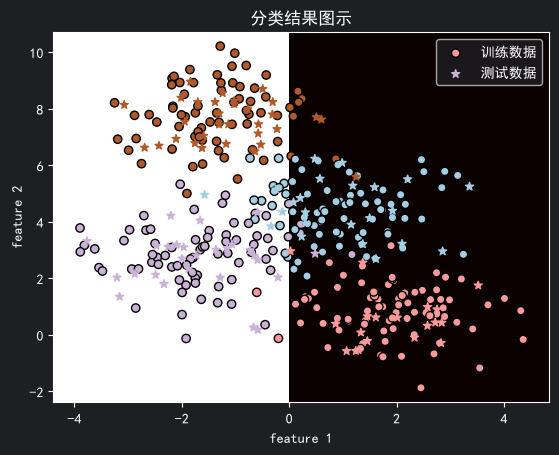

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.sans-serif'] = ['SimHei']    # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False      # 用来正常显示负号

# 限定横轴与纵轴的最大值、最小值
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

# 生成网格坐标矩阵
xx, yy = np.meshgrid(np.arange(x_min, x_max, .02),
                     np.arange(y_min, y_max, .02))

# 预测数据的类别标签
z = ber_nb.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# 用不同的背景色表示不同的分类
plt.pcolormesh(xx, yy, z, cmap=plt.cm.hot)

# 将训练集和测试集用散点图表示
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=plt.cm.Paired,
            edgecolors='k', label='训练数据')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=plt.cm.Paired, marker='*',
            label='测试数据')

plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.title('分类结果图示')
plt.legend()
plt.show()

In [3]:
from sklearn.naive_bayes import GaussianNB

# 使用高斯朴素贝叶斯拟合数据
gau_nb = GaussianNB()
gau_nb.fit(X_train, y_train)

print('高斯朴素贝叶斯模型得分: {:.2f}'.format(gau_nb.score(X_test, y_test)))

高斯朴素贝叶斯模型得分: 0.92


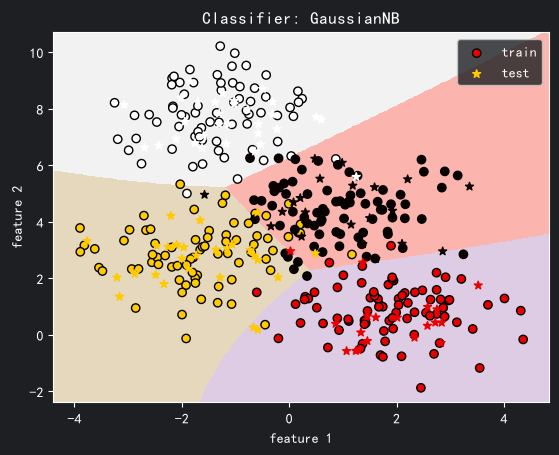

In [4]:
# 预测数据的类别标签
z = gau_nb.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# 用不同的色块来表示不同的分类
plt.pcolormesh(xx, yy, z, cmap=plt.cm.Pastel1)

# 将训练集和测试集用散点图表示
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=plt.cm.hot,
            edgecolors='k', label='train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=plt.cm.hot, marker='*',
            label='test')

plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.title('Classifier: GaussianNB')
plt.legend()
plt.show()

# 多项式贝叶斯模型

## 适用于数据离散型